# Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
rng = np.random.default_rng(100)

def purchase_probability(price):
    price = np.asarray(price, dtype=float)
    return (
        0.55 * np.exp(-np.logaddexp(0.0, (price - 13.9) / 0.8))
        + 0.30 * np.exp(-np.logaddexp(0.0, (price - 30.9) / 1.2))
        + 0.15 * np.exp(-np.logaddexp(0.0, (price - 58.4) / 1.8))
    )

def sales(price=14.0, rng=None, mean_customers=30):
    price = float(price)
    if not np.isfinite(price):
        raise ValueError("price must be finite")
    if price < 0:
        raise ValueError("price must be nonnegative")
    mean_customers = float(mean_customers)
    if not np.isfinite(mean_customers) or mean_customers < 0:
        raise ValueError("mean_customers must be finite and nonnegative")
    rng = np.random.default_rng(rng)
    customer_count = rng.poisson(mean_customers)
    probability = purchase_probability(price)
    return rng.binomial(1, probability, size=customer_count).astype(np.int8)

# 'track every consumer' requirement

In [4]:
total_customers = 0
total_revenue = 0.0
history = {}
log = []     # one row per experiment

def customer_to_revenue(price, n, phase=""):          # phase argument for tracking
    global total_customers, total_revenue
    buys = sales(price, rng=rng, mean_customers=n)
    revenue = buys * price

    total_customers += len(revenue)
    total_revenue += revenue.sum()

    # record this experiment for results in report later
    log.append({"phase": phase, "price": price, "customers": len(revenue), "revenue": revenue.sum()})

    # save my data so repeat tests at this price get pooled together
    if price in history:
        history[price] = np.concatenate([history[price], revenue])
    else:
        history[price] = revenue
    return revenue

# comparison function for difference in means, se of difference, and a confidence interval and a little helper function to compute stats

In [5]:
def price_stats(price):
    r = history[price] # all per customer revenue saved at THIS PRICE
    n = len(r) # how many customers tested at THIS PRICE
    mean = r.mean() # average revenue per customer
    se = r.std(ddof=1) / np.sqrt(n) # standard error of average
    se = max(r.std(ddof=1) / np.sqrt(n), 0.1)
    return mean, se, n


In [6]:
def compare_prices(price_a, price_b, z=1.645): # default to 95% confidence
    mean_a, se_a, n_a = price_stats(price_a)
    mean_b, se_b, n_b = price_stats(price_b)

    diff = mean_b - mean_a
    se_diff = np.sqrt(se_a**2 + se_b**2)
    ci = (diff - z * se_diff, diff + z * se_diff)

    return diff, se_diff, ci

# trying grid search first

In [7]:
prices = [p for p in range(5,71, 5)] # skipping 0 because it obviously makes $0 every time
prices

[5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70]

In [8]:
CUSTOMERS = 100
grid_results = []
for p in prices:
    customer_to_revenue(p, CUSTOMERS, phase="grid")
    mean, se, n = price_stats(p)
    grid_results.append({"price": p, "mean": mean, "se": se, "n": n})

grid_df = pd.DataFrame(grid_results)
print(grid_df)



    price       mean        se    n
0       5   5.000000  0.100000  111
1      10  10.000000  0.100000  108
2      15   8.168317  0.747016  101
3      20  10.275229  0.961886  109
4      25  11.734694  1.266802   98
5      30   8.613861  1.357266  101
6      35   5.990991  1.256954  111
7      40   6.315789  1.504399   95
8      45   6.750000  1.472971  120
9      50   6.018519  1.572852  108
10     55  11.578947  2.312708   95
11     60   0.645161  0.645161   93
12     65   0.000000  0.100000   87
13     70   0.000000  0.100000  101


In [9]:
best_row = grid_df.loc[grid_df["mean"].idxmax()] # find index of row with largest mean

print(best_row)

top3 = grid_df.nlargest(3, "mean") # get 3 largest candidates
print(top3)

price    25.000000
mean     11.734694
se        1.266802
n        98.000000
Name: 4, dtype: float64
    price       mean        se    n
4      25  11.734694  1.266802   98
10     55  11.578947  2.312708   95
3      20  10.275229  0.961886  109


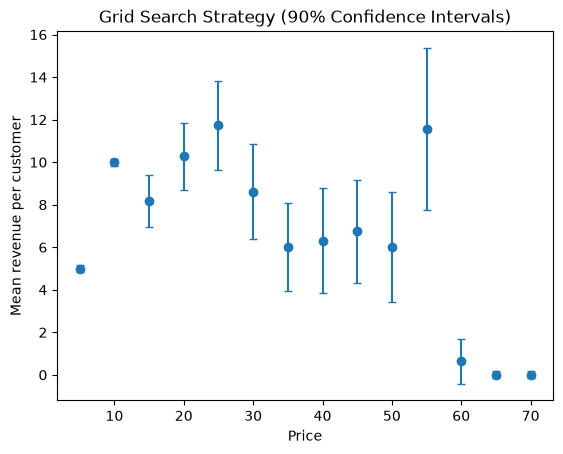

In [10]:
plt.errorbar(grid_df['price'], grid_df['mean'], yerr=1.645 * grid_df['se'], # plot price by mean with error bars at 90% * standard error
            fmt='o', capsize=3)
plt.xlabel("Price")
plt.ylabel("Mean revenue per customer")
plt.title("Grid Search Strategy (90% Confidence Intervals)")
plt.show()

# Clear winners from above search method are $55, $25, $20, $15, $10

In [11]:
def eliminate_candidates(candidates, n_add=100, z=1.645, max_rounds=5):
    survivors = list(candidates)
    for rnd in range(max_rounds):
        # collect more data for each surviving price
        for p in survivors:
            customer_to_revenue(p, n_add, phase="elimination")

        # find bounds for each price
        bounds = {}
        for p in survivors:
            mean, se, n = price_stats(p)
            bounds[p] = (mean - se*z, mean+se*z)

        # find BEST lower bound
        best_lower = max(lower for lower, _ in bounds.values())

        # keeping prices whose upper bound is still capable of hitting BEST lower bound
        survivors = [p for p in survivors if bounds[p][1] >= best_lower]

        print(f"Round {rnd+1}: survivors = {survivors}")

        if len(survivors) == 1:
            break
    return survivors

In [12]:
candidates = grid_df.nlargest(5, "mean")['price'].to_list()
best_candidates = eliminate_candidates(candidates)
print(best_candidates)

Round 1: survivors = [25, 55, 30]
Round 2: survivors = [25, 55, 30]
Round 3: survivors = [25, 55, 30]
Round 4: survivors = [25, 30]
Round 5: survivors = [25, 30]
[25, 30]


# Trying to refine between 25 and 30

In [13]:
def refine(survivors, n=150, step=1.0, rounds=2):
    lo, hi, = min(survivors) - 5, max(survivors) + 5 # search a bit past survivor
    best = None
    for rnd in range(rounds):
        test_prices = [round(p, 2) for p in np.arange(lo, hi + 1e-9, step)] # arange stops before end of range so adding 1e-9 to make sure hi is included
        for p in test_prices:
            customer_to_revenue(p, n, phase="refinement")
        best = max(test_prices, key=lambda p: price_stats(p)[0]) # give me item from this list that scores highest where score is computed by this function
        print(f"Refine round {rnd+1}: best = {best}")
        # zoom in around the best and use a finer step
        lo, hi = best - step, best + step
        step = step / 4

    return best
final_price = refine(best_candidates)

Refine round 1: best = 27.0
Refine round 2: best = 27.0


In [14]:
OPTIMAL = 11.925
rev_per_customer = total_revenue / total_customers

summary = pd.DataFrame({
    "Metric": ["Final price", "Customers experimented on", "Revenue during experiments",
               "Revenue per customer", "% of optimal captured"],
    "Value": [f"${final_price:.2f}", f"{total_customers:,}", f"${total_revenue:,.2f}",
              f"${rev_per_customer:.2f}", f"{100 * rev_per_customer / OPTIMAL:.1f}%"],
})
summary

,Metric,Value
0,Final price,$27.00
1,Customers experimented on,"6,933"
2,Revenue during experiments,"$64,926.75"
3,Revenue per customer,$9.36
4,% of optimal captured,78.5%


In [15]:
log_df = pd.DataFrame(log)

phase_table = log_df.groupby("phase", sort=False).agg(
    customers=("customers", "sum"),
    revenue=("revenue", "sum"),
)
phase_table.loc["Total"] = [log_df["customers"].sum(), log_df["revenue"].sum()]
phase_table["rev_per_customer"] = phase_table["revenue"] / phase_table["customers"]
phase_table["pct_of_optimal"] = 100 * phase_table["rev_per_customer"] / OPTIMAL
phase_table.round(2)

,customers,revenue,rev_per_customer,pct_of_optimal
phase,,,,
grid,1438.0,9485.00,6.60,55.31
elimination,1630.0,15210.00,9.33,78.25
refinement,3865.0,40231.75,10.41,87.29
Total,6933.0,64926.75,9.36,78.53
